(p4-lab-decision-trees-ensemble)=
# P4 실습: 결정 트리와 앙상블 학습

**감사의 글**

이번 실습은 제공된 `decision_trees.ipynb`, `ensemble_learning.ipynb`, `code-decision_trees.ipynb`, `code-ensemble_learning.ipynb`를 바탕으로 구성했다. 원본의 붓꽃·초승달 데이터, 결정 트리 규제, 배깅과 OOB 평가, 랜덤 포레스트, 그레이디언트 부스팅 예제를 활용한다.

**주요 내용**

P1에서 모델 선택·검증·일반화를, P2에서 분류 모델과 평가를, P3에서 손실을 줄이는 학습 원리를 살펴보았다. 이번 P4에서는 **결정 트리가 데이터를 어떻게 나누는지**, 그리고 **여러 결정 트리를 결합하면 어떤 차이가 생기는지** 확인한다.

> **결정 트리의 분할 → 트리 복잡도와 과대적합 → 배깅과 특성 선택 → OOB 평가 → 랜덤 포레스트 분류·회귀 → 부스팅 회귀·분류**

각 단계에서 코드를 직접 실행하고, 그래프와 검증 성능을 해석한다.

## 환경설정

필수 라이브러리: NumPy, pandas, Matplotlib, scikit-learn. Graphviz와 XGBoost는 필수 실행에 사용하지 않는다. 실행 환경이 다르면 수치가 조금 달라질 수 있다.

In [24]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.datasets import load_iris, make_moons
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, RandomForestRegressor, GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, mean_squared_error

print('Python:', sys.version.split()[0])
print('scikit-learn:', sklearn.__version__)

Python: 3.13.12
scikit-learn: 1.8.0


## 1단계: 결정 트리는 어떻게 분류하는가?

결정 트리는 입력 특성에 관한 질문을 반복하여 데이터를 나눈다. 각 갈림길의 조건을 따라 내려가면 마지막 **잎 노드**(leaf node)에서 예측이 결정된다. 이 예제에서는 붓꽃의 꽃잎 길이와 너비만 사용한다.

In [25]:
iris = load_iris(as_frame=True)
feature_names = ['petal length (cm)', 'petal width (cm)']
X_iris = iris.data[feature_names]
y_iris = iris.target

print(X_iris.head())
print('클래스:', list(iris.target_names))

   petal length (cm)  petal width (cm)
0                1.4               0.2
1                1.4               0.2
2                1.3               0.2
3                1.5               0.2
4                1.4               0.2
클래스: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


### 트리를 훈련하고 구조 확인하기

`max_depth`는 결정 트리가 루트 노드에서 잎 노드까지 얼마나 깊게 분할할 수 있는지 정하는 **하이퍼파라미터**(hyperparameter)다. 루트 노드의 깊이는 0이다.

먼저 `max_depth=2`로 트리를 훈련한다. 트리 그림에서 각 노드의 분할 특성, 임곗값, 불순도와 샘플 수를 관찰하자.

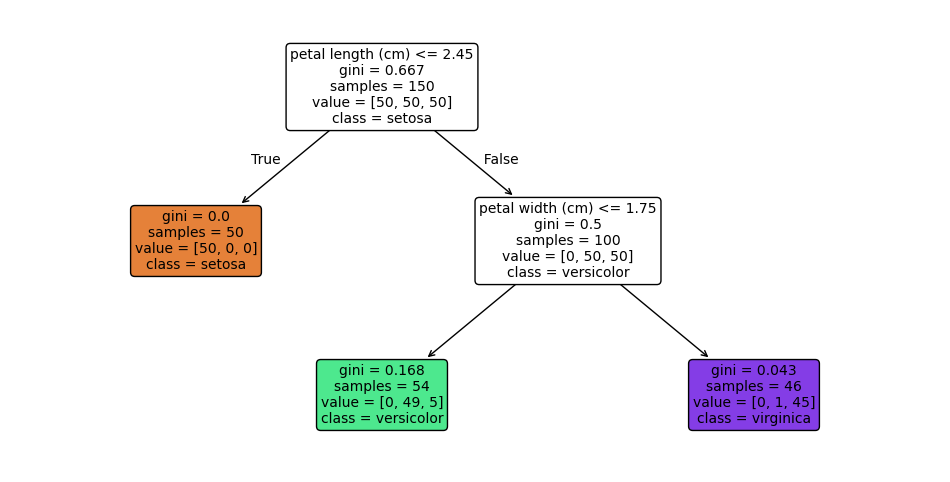

In [26]:
tree_clf = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_clf.fit(X_iris, y_iris)

plt.figure(figsize=(12, 6))
plot_tree(tree_clf, feature_names=feature_names, class_names=iris.target_names, filled=True, rounded=True, fontsize=10)
plt.show()

### 깊이가 2인 트리와 3인 트리 비교하기

이번에는 같은 붓꽃 데이터와 같은 특성을 사용하되 `max_depth=3`으로 트리를 훈련한다.

- `max_depth=2`: 루트에서 최대 두 번의 분할을 거쳐 잎 노드에 도달한다.
- `max_depth=3`: 필요한 경우 한 번 더 분할할 수 있으므로 더 세밀한 규칙을 만들 수 있다.

**`max_depth=3`이라고 해서 모든 가지가 깊이 3까지 자라는 것은 아니다.** 추가 분할이 필요하지 않으면 더 일찍 멈출 수 있다. 아래 두 트리의 실제 깊이, 잎 노드 수와 구조를 비교해 보자.

         모델  실제 깊이  잎 노드 수   훈련 정확도
max_depth=2      2       3 0.960000
max_depth=3      3       5 0.973333


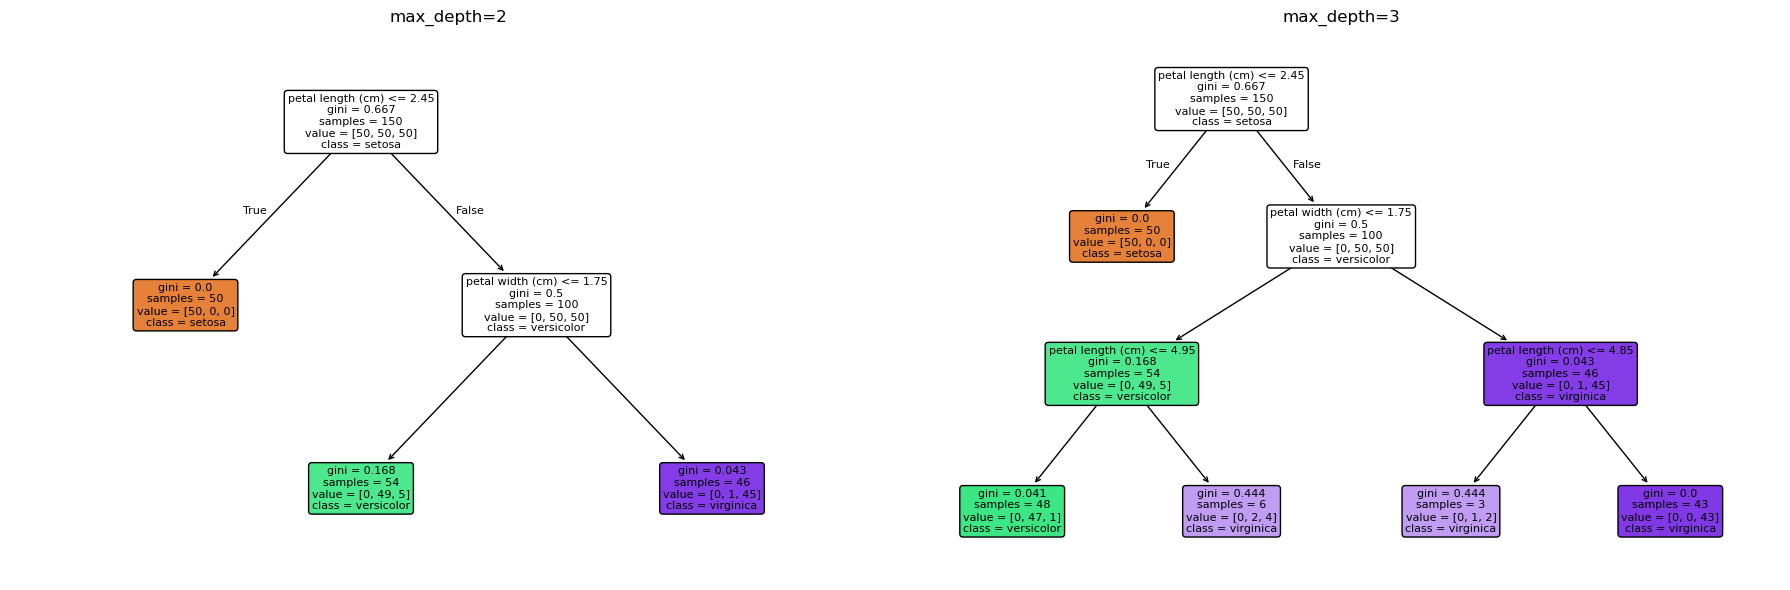

In [27]:
tree_clf_depth3 = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_clf_depth3.fit(X_iris, y_iris)

comparison = pd.DataFrame({
    "모델": ["max_depth=2", "max_depth=3"],
    "실제 깊이": [tree_clf.get_depth(), tree_clf_depth3.get_depth()],
    "잎 노드 수": [tree_clf.get_n_leaves(), tree_clf_depth3.get_n_leaves()],
    "훈련 정확도": [tree_clf.score(X_iris, y_iris), tree_clf_depth3.score(X_iris, y_iris)]
})
print(comparison.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, (name, model) in zip(axes, [("max_depth=2", tree_clf), ("max_depth=3", tree_clf_depth3)]):
    plot_tree(model, feature_names=feature_names, class_names=list(iris.target_names), filled=True, rounded=True, fontsize=8, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### 예측 클래스와 예측 확률

새 샘플은 트리의 분할 규칙을 따라 한 잎에 도착한다. `predict_proba()`는 해당 잎의 훈련 샘플들이 각 클래스에 속하는 비율에 기초한 확률을 반환한다.

In [28]:
sample = pd.DataFrame([[5.0, 1.5]], columns=feature_names)
print('예측 확률:', tree_clf.predict_proba(sample).round(3))
print('예측 클래스:', iris.target_names[tree_clf.predict(sample)[0]])

예측 확률: [[0.    0.907 0.093]]
예측 클래스: versicolor


### 결정 경계 확인하기

트리는 축에 수직인 분할을 반복한다. 아래 그림에서 영역의 색이 바뀌는 위치와 트리의 임곗값을 비교한다.

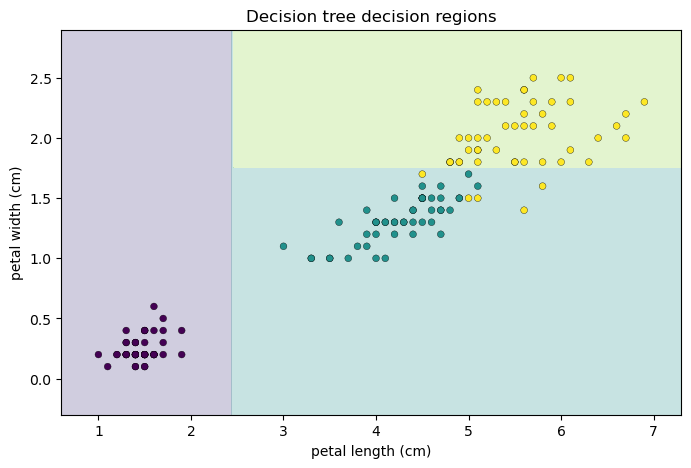

In [29]:
xx, yy = np.meshgrid(np.linspace(X_iris.iloc[:, 0].min()-0.4, X_iris.iloc[:, 0].max()+0.4, 250), np.linspace(X_iris.iloc[:, 1].min()-0.4, X_iris.iloc[:, 1].max()+0.4, 250))
mesh = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=feature_names)
zz = tree_clf.predict(mesh).reshape(xx.shape)
plt.figure(figsize=(8, 5))
plt.contourf(xx, yy, zz, levels=[-0.5,0.5,1.5,2.5], alpha=0.25)
plt.scatter(X_iris.iloc[:, 0], X_iris.iloc[:, 1], c=y_iris, s=24, edgecolors='k', linewidths=0.25)
plt.xlabel(feature_names[0]); plt.ylabel(feature_names[1]); plt.title('Decision tree decision regions')
plt.show()

### 깊이에 따른 결정 경계 비교하기

두 모델의 결정 경계를 같은 축에서 비교해 보자. 깊이 3인 트리는 깊이 2인 트리보다 영역을 더 세분할 **수 있지만**, 훈련 정확도가 높아진다고 해서 새로운 데이터의 성능도 반드시 높아지는 것은 아니다. 일반화 성능 비교는 2단계에서 훈련셋과 테스트셋을 나누어 살펴본다.

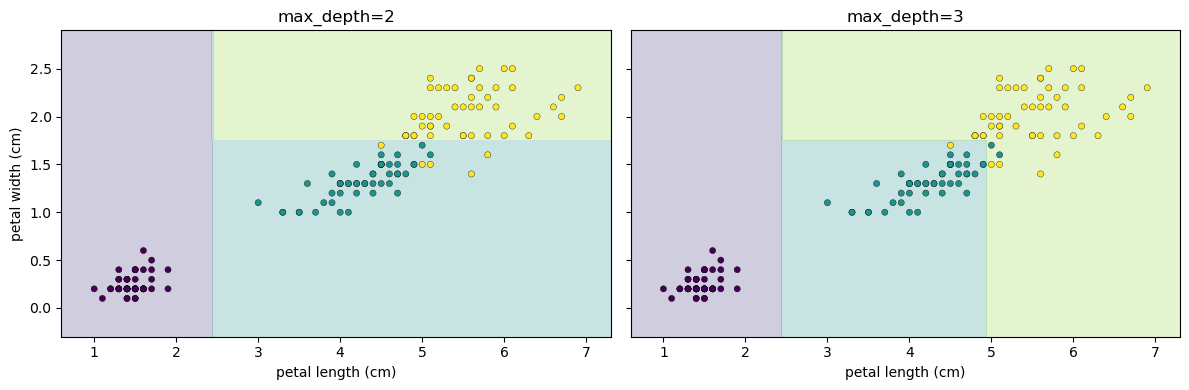

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for ax, (name, model) in zip(axes, [("max_depth=2", tree_clf), ("max_depth=3", tree_clf_depth3)]):
    zz = model.predict(mesh).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5, 2.5], alpha=0.25)
    ax.scatter(X_iris.iloc[:, 0], X_iris.iloc[:, 1], c=y_iris, s=20, edgecolors="k", linewidths=0.25)
    ax.set_xlabel(feature_names[0])
    ax.set_title(name)
axes[0].set_ylabel(feature_names[1])
plt.tight_layout()
plt.show()

**확인 질문**

- 결정 트리가 새 샘플을 분류하는 과정을 루트 노드, 분할 조건, 잎 노드로 설명해 보자.
- 트리의 `max_depth`는 **모델 파라미터**와 **하이퍼파라미터** 중 무엇인가?
- 결정 경계가 주로 가로·세로 선으로 나타나는 이유는 무엇인가?
- `max_depth=2`와 `max_depth=3`의 트리 그림 및 결정 경계를 비교했을 때 어떤 분할이 추가되었는가?
- `max_depth=3`의 훈련 정확도가 같거나 높더라도 테스트 성능까지 더 좋다고 말할 수 있는가?

## 2단계: 트리가 복잡해지면 성능은 어떻게 변하는가?

초승달 데이터로 훈련셋과 테스트셋을 나눈다. 훈련 성능뿐 아니라 별도로 보관한 테스트 성능을 함께 살펴보자. 이 절에서는 모델 구조의 차이를 시각화하기 위해 두 모델만 비교하며, 테스트셋을 이용해 하이퍼파라미터를 탐색하지 않는다.

In [31]:
X_moons, y_moons = make_moons(n_samples=500, noise=0.25, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X_moons, y_moons, test_size=0.25, stratify=y_moons, random_state=42)
print('훈련:', X_train.shape, '테스트:', X_test.shape)

훈련: (375, 2) 테스트: (125, 2)


### 규제하지 않은 트리와 규제한 트리 비교

`min_samples_leaf=5`는 잎 노드에 남아야 하는 최소 훈련 샘플 수를 제한한다. 이러한 제한은 복잡한 분할을 억제한다.

In [32]:
tree_full = DecisionTreeClassifier(random_state=42)
tree_regularized = DecisionTreeClassifier(min_samples_leaf=5, random_state=42)

rows = []
for name, model in [('No limit', tree_full), ('min_samples_leaf=5', tree_regularized)]:
    model.fit(X_train, y_train)
    rows.append({'모델': name, '훈련 정확도': accuracy_score(y_train, model.predict(X_train)), '테스트 정확도': accuracy_score(y_test, model.predict(X_test)), '트리 깊이': model.get_depth(), '잎 개수': model.get_n_leaves()})
pd.DataFrame(rows)

,모델,훈련 정확도,테스트 정확도,트리 깊이,잎 개수
0,No limit,1.000000,0.952,8,24
1,min_samples_leaf=5,0.978667,0.944,7,17


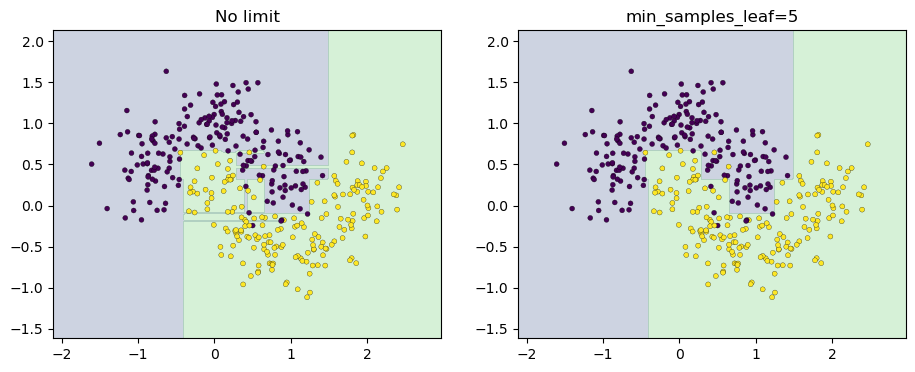

In [33]:
def plot_regions(ax, model, X, y, title):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min()-0.5, X[:, 0].max()+0.5, 250), np.linspace(X[:, 1].min()-0.5, X[:, 1].max()+0.5, 250))
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, levels=[-0.5, 0.5, 1.5])
    ax.scatter(X[:, 0], X[:, 1], c=y, s=13, edgecolors='k', linewidths=0.2)
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_regions(axes[0], tree_full, X_train, y_train, 'No limit')
plot_regions(axes[1], tree_regularized, X_train, y_train, 'min_samples_leaf=5')
plt.show()

**확인 질문**

- 훈련 정확도가 더 높다고 해서 반드시 일반화 성능이 더 좋은가?
- `min_samples_leaf`를 크게 하면 트리 구조는 일반적으로 어떻게 달라지는가?
- 결정 트리가 과대적합하기 쉬운 이유를 그림과 함께 설명해 보자.

### 교차 검증으로 복잡도 선택하기

P1에서 사용한 `GridSearchCV`를 결정 트리에도 적용할 수 있다. 후보 하이퍼파라미터는 **훈련셋 내부의 교차 검증**으로 선택하고, 테스트셋은 마지막에만 평가한다.

In [34]:
param_grid = {'max_depth': [2, 3, 4, 6, None], 'min_samples_leaf': [1, 3, 5, 10]}
search = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
search.fit(X_train, y_train)

print('선택된 설정:', search.best_params_)
print('교차 검증 정확도:', round(search.best_score_, 3))
print('최종 테스트 정확도:', round(search.best_estimator_.score(X_test, y_test), 3))

선택된 설정: {'max_depth': 6, 'min_samples_leaf': 5}
교차 검증 정확도: 0.941
최종 테스트 정확도: 0.944


## 3단계: 여러 트리의 예측을 결합하면 어떻게 될까?

**앙상블 학습**(ensemble learning)은 여러 예측기의 결과를 결합한다. **배깅**(bagging)은 훈련셋에서 중복을 허용하여 샘플을 뽑는 **부트스트랩**(bootstrap)을 이용해 각 모델을 훈련한다. 분류에서는 여러 모델의 예측을 결합한다.

`BaggingClassifier`의 기본 설정은 **각 모델에서 모든 특성을 사용**(`max_features=1.0`)하면서, **샘플은 복원추출**(`bootstrap=True`)하는 것이다. `max_samples=1.0`이어도 복원추출이므로 같은 샘플이 여러 번 선택되고 선택되지 않은 샘플도 생긴다.

`max_features`를 줄이면 **트리마다 사용할 특성의 일부를 선택**할 수 있다. 이 선택은 각 트리를 훈련할 때 이루어지고, 랜덤 포레스트처럼 **각 노드에서 새롭게 특성을 선택**하는 방식과는 다르다.

In [35]:
bag_clf = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42), n_estimators=100, max_samples=0.8, max_features=1.0, bootstrap=True, oob_score=True, random_state=42, n_jobs=-1)
bag_clf.fit(X_train, y_train)

comparison = pd.DataFrame([
    {'모델': 'Single tree', '훈련 정확도': tree_full.score(X_train, y_train), '테스트 정확도': tree_full.score(X_test, y_test)},
    {'모델': 'Bagging trees', '훈련 정확도': bag_clf.score(X_train, y_train), '테스트 정확도': bag_clf.score(X_test, y_test)}
])
comparison

,모델,훈련 정확도,테스트 정확도
0,Single tree,1.000000,0.952
1,Bagging trees,0.997333,0.952


### OOB 평가 이해하기

부트스트랩 추출에서 특정 트리의 훈련에 선택되지 않은 샘플을 **OOB**(out-of-bag) 샘플이라고 한다. 이를 이용해 훈련 과정 안에서 추가적인 평가 신호를 얻을 수 있다. OOB가 별도의 최종 테스트셋을 대신하는 것은 아니다.

In [36]:
print('OOB 정확도:', round(bag_clf.oob_score_, 3))
print('최종 테스트 정확도:', round(bag_clf.score(X_test, y_test), 3))

OOB 정확도: 0.949
최종 테스트 정확도: 0.952


**확인 질문**

- 배깅에서 부트스트랩은 무엇을 의미하는가?
- 하나의 트리와 여러 트리의 투표 결과가 달라질 수 있는 이유는 무엇인가?
- OOB 샘플은 어떤 트리에 대해 '훈련에 사용되지 않은 샘플'인가?
- `max_samples=0.8`과 `max_features=1.0`은 각각 무엇을 지정하는가?

## 4단계: 랜덤 포레스트는 배깅과 무엇이 다른가?

**랜덤 포레스트**(random forest)는 여러 결정 트리를 결합할 뿐 아니라 **각 노드에서 분할 후보 특성을 무작위로 선택**한다. 반면 앞 단계의 기본 `BaggingClassifier`는 각 트리가 모든 특성을 사용할 수 있다.

예를 들어 `RandomForestClassifier(max_features="sqrt")`는 각 분할에서 전체 특성 수의 제곱근 정도를 후보로 고려한다. `BaggingClassifier(max_features=0.7)`은 **트리마다 사용할 특성 70%를 미리 선택**한다는 점이 다르다.

분류에서는 나무들의 결과를 결합하고, 회귀에서는 여러 트리의 예측값을 **평균**한다.

In [37]:
forest = RandomForestClassifier(n_estimators=200, max_features='sqrt', random_state=42, n_jobs=-1)
forest.fit(X_train, y_train)

pd.DataFrame([
    {'모델': 'Decision tree', '훈련 정확도': tree_full.score(X_train, y_train), '테스트 정확도': tree_full.score(X_test, y_test)},
    {'모델': 'Bagging', '훈련 정확도': bag_clf.score(X_train, y_train), '테스트 정확도': bag_clf.score(X_test, y_test)},
    {'모델': 'Random forest', '훈련 정확도': forest.score(X_train, y_train), '테스트 정확도': forest.score(X_test, y_test)}
])

,모델,훈련 정확도,테스트 정확도
0,Decision tree,1.000000,0.952
1,Bagging,0.997333,0.952
2,Random forest,1.000000,0.944


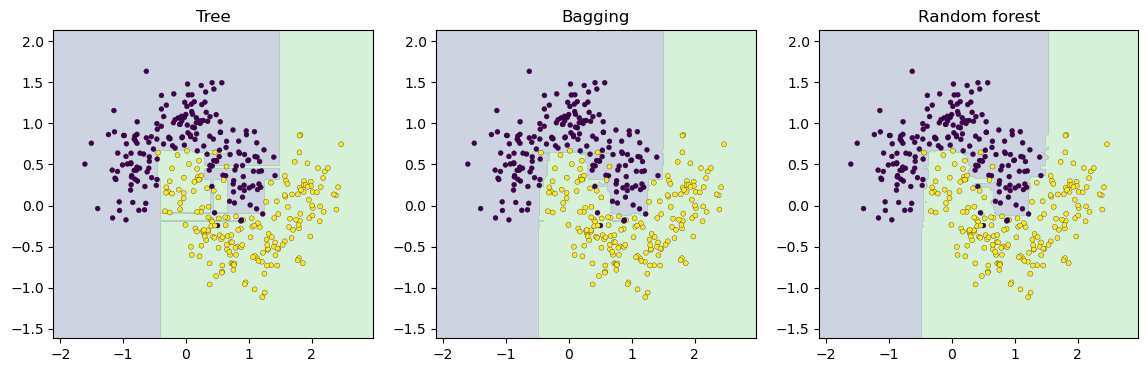

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, model) in zip(axes, [('Tree', tree_full), ('Bagging', bag_clf), ('Random forest', forest)]):
    plot_regions(ax, model, X_train, y_train, name)
plt.show()

### 특성 중요도 해석

랜덤 포레스트의 `feature_importances_`는 트리 분할 과정에서 불순도를 줄인 정도를 바탕으로 산출한 값이다. 크다고 해서 인과관계가 입증되거나, 해당 특성만으로 결과를 설명할 수 있는 것은 아니다.

petal length (cm)    0.459290
petal width (cm)     0.417860
sepal length (cm)    0.101969
sepal width (cm)     0.020881
dtype: float64


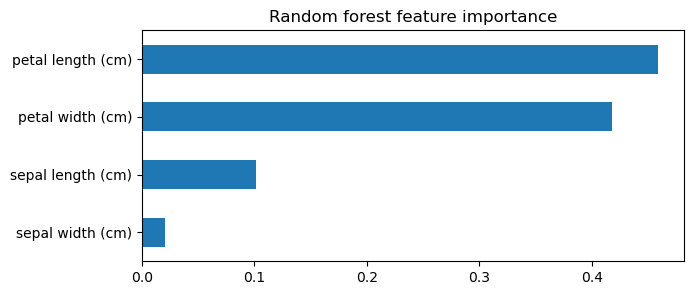

In [39]:
forest_iris = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
forest_iris.fit(iris.data, iris.target)
importance = pd.Series(forest_iris.feature_importances_, index=iris.feature_names).sort_values(ascending=False)
print(importance)
importance.sort_values().plot.barh(figsize=(7, 3), title='Random forest feature importance')
plt.show()

**확인 질문**

- 랜덤 포레스트와 단일 결정 트리의 차이를 설명해 보자.
- 특성 중요도가 높다는 사실만으로 인과관계를 주장할 수 있는가?
- 여러 트리의 예측 결과를 결합하는 이유는 무엇인가?

### 랜덤 포레스트 회귀: 여러 트리의 예측값 평균하기

랜덤 포레스트는 연속적인 숫자를 예측하는 **회귀**(regression)에도 사용할 수 있다. 아래에서는 곡선 형태의 데이터를 훈련셋과 검증셋으로 나누고, 단일 회귀 트리와 랜덤 포레스트를 비교한다. 랜덤 포레스트 회귀는 **여러 회귀 트리의 예측값을 평균**한다.

In [40]:
rng_reg = np.random.default_rng(42)
X_reg = rng_reg.uniform(-0.5, 0.5, size=(240, 1))
y_reg = 3 * X_reg[:, 0] ** 2 + 0.10 * rng_reg.standard_normal(240)
X_reg_train, X_reg_val, y_reg_train, y_reg_val = train_test_split(X_reg, y_reg, test_size=0.25, random_state=42)

reg_models = {
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
}
reg_results = []
for name, model in reg_models.items():
    model.fit(X_reg_train, y_reg_train)
    reg_results.append({"모델": name, "훈련 RMSE": np.sqrt(mean_squared_error(y_reg_train, model.predict(X_reg_train))), "검증 RMSE": np.sqrt(mean_squared_error(y_reg_val, model.predict(X_reg_val)))})
pd.DataFrame(reg_results)

,모델,훈련 RMSE,검증 RMSE
0,Decision Tree,0.00000,0.145013
1,Random Forest,0.04516,0.121820


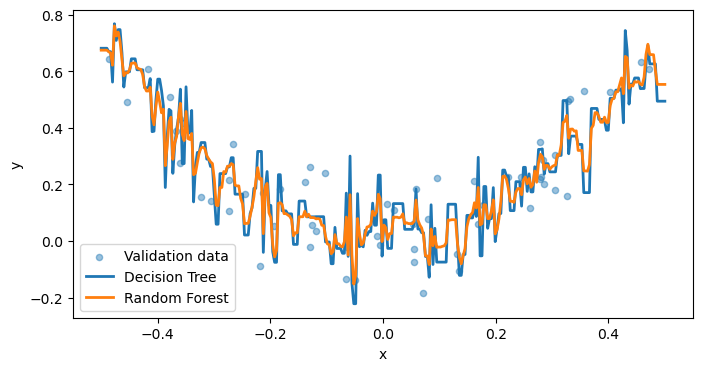

In [41]:
x_grid = np.linspace(-0.5, 0.5, 300).reshape(-1, 1)
plt.figure(figsize=(8, 4))
plt.scatter(X_reg_val[:, 0], y_reg_val, s=20, alpha=0.45, label="Validation data")
for name, model in reg_models.items():
    plt.plot(x_grid[:, 0], model.predict(x_grid), linewidth=2, label=name)
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

**확인 질문**

- 랜덤 포레스트 회귀가 여러 트리의 결과를 결합하는 방법은 무엇인가?
- 단일 회귀 트리와 랜덤 포레스트의 **훈련 RMSE와 검증 RMSE**를 비교해 보자. 어느 쪽이 더 잘 일반화되었는가?
- 랜덤 포레스트가 모든 데이터에서 항상 더 좋은 성능을 낼 것이라고 단정할 수 있는가?

## 5단계: 회귀 결정 트리와 부스팅

결정 트리는 분류뿐 아니라 회귀에도 사용된다. 회귀 트리에서는 각 잎의 예측값이 연속적인 숫자이며, 같은 잎에 속하는 샘플은 같은 예측값을 받는다.

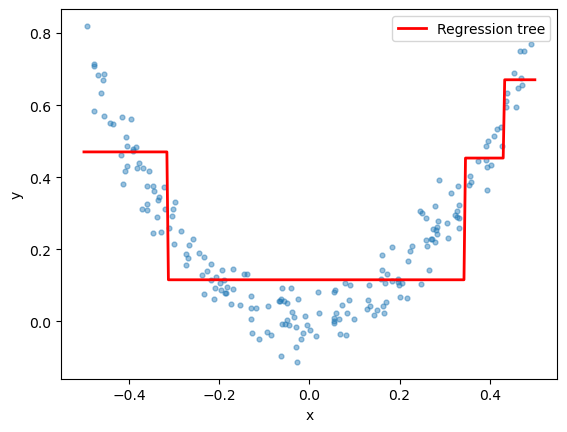

In [42]:
rng = np.random.default_rng(42)
X_quad = rng.uniform(-0.5, 0.5, size=(200, 1))
y_quad = 3 * X_quad[:, 0] ** 2 + 0.05 * rng.standard_normal(200)

reg_tree = DecisionTreeRegressor(max_depth=2, random_state=42)
reg_tree.fit(X_quad, y_quad)

grid = np.linspace(-0.5, 0.5, 300).reshape(-1, 1)
plt.scatter(X_quad[:, 0], y_quad, s=12, alpha=0.45)
plt.plot(grid[:, 0], reg_tree.predict(grid), 'r-', linewidth=2, label='Regression tree')
plt.xlabel('x'); plt.ylabel('y'); plt.legend(); plt.show()

### 부스팅은 이전 모델의 오류를 어떻게 보완할까?

**그레이디언트 부스팅**(gradient boosting)은 모델을 순차적으로 추가한다. 아래 회귀 예제에서는 첫 모델의 예측 후 남은 **잔차**(실제값 − 예측값)를 다음 결정 트리가 학습한다. 세 모델의 예측을 합하면 최종 예측이 된다.

In [43]:
boost_tree_1 = DecisionTreeRegressor(max_depth=2, random_state=42)
boost_tree_1.fit(X_quad, y_quad)
residual_1 = y_quad - boost_tree_1.predict(X_quad)

boost_tree_2 = DecisionTreeRegressor(max_depth=2, random_state=43)
boost_tree_2.fit(X_quad, residual_1)
residual_2 = residual_1 - boost_tree_2.predict(X_quad)

boost_tree_3 = DecisionTreeRegressor(max_depth=2, random_state=44)
boost_tree_3.fit(X_quad, residual_2)

pred_1 = boost_tree_1.predict(X_quad)
pred_3 = pred_1 + boost_tree_2.predict(X_quad) + boost_tree_3.predict(X_quad)
print('트리 1개 MSE:', round(mean_squared_error(y_quad, pred_1), 4))
print('트리 3개 합산 MSE:', round(mean_squared_error(y_quad, pred_3), 4))

트리 1개 MSE: 0.0127
트리 3개 합산 MSE: 0.0043


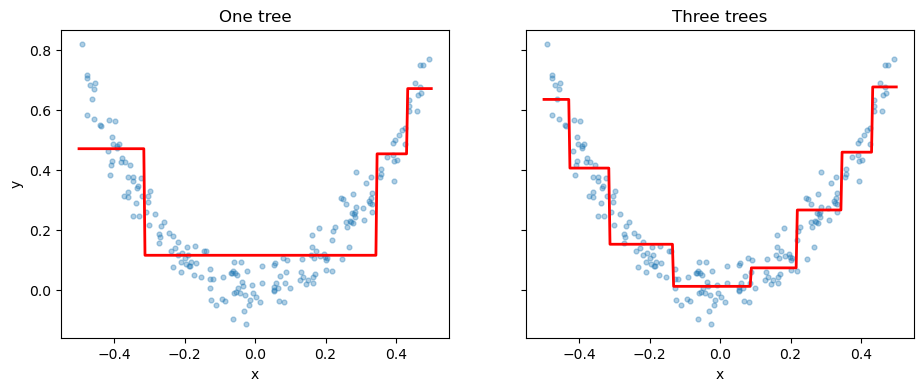

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, estimators) in zip(axes, [('One tree', [boost_tree_1]), ('Three trees', [boost_tree_1, boost_tree_2, boost_tree_3])]):
    predicted = sum(est.predict(grid) for est in estimators)
    ax.scatter(X_quad[:, 0], y_quad, s=12, alpha=0.35)
    ax.plot(grid[:, 0], predicted, 'r-', linewidth=2)
    ax.set_title(name); ax.set_xlabel('x')
axes[0].set_ylabel('y')
plt.show()

### `GradientBoostingRegressor`로 확인하기

위 과정을 직접 구현하지 않고 사이킷런의 그레이디언트 부스팅 회귀 모델을 사용할 수 있다. `learning_rate`는 새로 추가되는 트리의 기여 정도를 조절한다. 이는 P3에서 배운 파라미터 업데이트의 학습률과 이름은 같지만 **적용되는 대상이 다르다**.

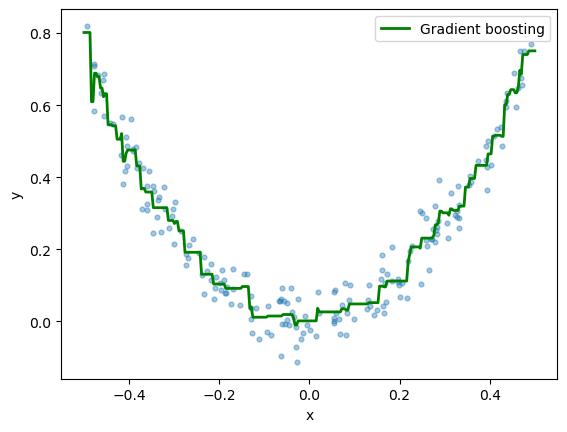

In [45]:
gbrt = GradientBoostingRegressor(max_depth=2, n_estimators=100, learning_rate=0.1, random_state=42)
gbrt.fit(X_quad, y_quad)

plt.scatter(X_quad[:, 0], y_quad, s=12, alpha=0.4)
plt.plot(grid[:, 0], gbrt.predict(grid), 'g-', linewidth=2, label='Gradient boosting')
plt.xlabel('x'); plt.ylabel('y'); plt.legend(); plt.show()

### 과대적합을 피하려면?

트리 개수(`n_estimators`), 각 트리 깊이(`max_depth`), 학습률(`learning_rate`)은 모델 복잡도와 예측에 영향을 준다. 실제 모델 선택에서는 P1과 마찬가지로 검증 데이터나 교차 검증을 활용해야 한다. 아래의 훈련 성능은 **최종 일반화 성능이 아니다.**

In [46]:
rows = []
for n in [1, 5, 20, 100]:
    model = GradientBoostingRegressor(max_depth=2, n_estimators=n, learning_rate=0.1, random_state=42)
    model.fit(X_quad, y_quad)
    rows.append({'트리 개수': n, '훈련 MSE': mean_squared_error(y_quad, model.predict(X_quad))})
pd.DataFrame(rows)

,트리 개수,훈련 MSE
0,1,0.040499
1,5,0.023398
2,20,0.005075
3,100,0.001559


**확인 질문**

- 배깅은 여러 트리를 어떤 방식으로 훈련하고 결합하는가?
- 부스팅은 이전 트리의 오류를 다음 트리에서 어떻게 다루는가?
- 트리 수를 늘렸을 때 훈련 MSE가 감소했다면 테스트 성능도 반드시 좋아진다고 할 수 있는가?

### 그레이디언트 부스팅 분류: 랜덤 포레스트와 비교하기

부스팅은 회귀 전용 기법이 아니다. **그레이디언트 부스팅 분류**(gradient boosting classification)는 분류에서도 여러 트리를 **순차적으로 추가**하며 손실을 줄인다. 분류의 로그 손실을 줄이는 과정은 앞의 회귀 예제처럼 단순히 숫자 잔차를 따라가는 과정과 동일하지 않다.

아래에서는 2단계의 초승달 훈련셋을 사용하여 랜덤 포레스트와 그레이디언트 부스팅 분류 모델을 비교한다.

In [47]:
class_models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=2, random_state=42)
}
class_results = []
for name, model in class_models.items():
    model.fit(X_train, y_train)
    class_results.append({"모델": name, "훈련 정확도": accuracy_score(y_train, model.predict(X_train)), "테스트 정확도": accuracy_score(y_test, model.predict(X_test))})
pd.DataFrame(class_results)

,모델,훈련 정확도,테스트 정확도
0,Random Forest,1.000000,0.944
1,Gradient Boosting,0.986667,0.944


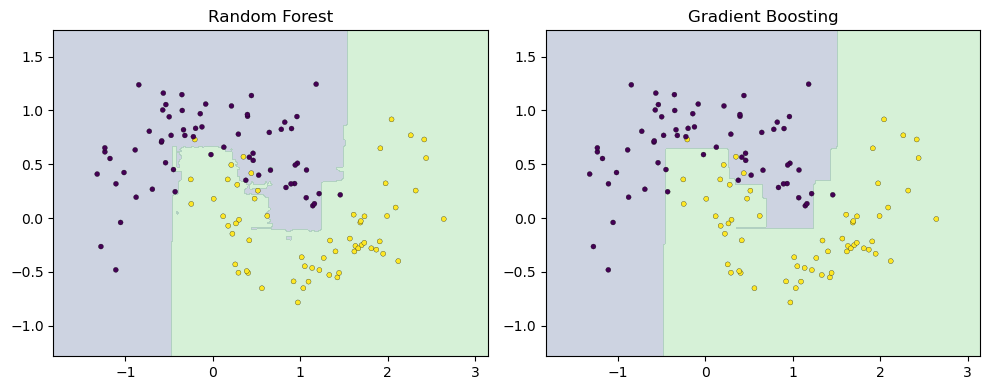

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, class_models.items()):
    plot_regions(ax, model, X_test, y_test, name)
plt.tight_layout()
plt.show()

**확인 질문**

- 랜덤 포레스트와 그레이디언트 부스팅은 여러 트리를 각각 어떤 순서로 학습하는가?
- 두 모델의 테스트 정확도를 비교해 보자. 이 결과만으로 어떤 모델이 항상 더 낫다고 할 수 있는가?
- 부스팅의 트리 수와 학습률을 조정할 때 왜 별도의 검증이 필요한가?

## 6단계: 세 가지 방법을 비교해 판단하기

실습에서 가장 중요한 것은 **모델의 이름을 외우는 것보다, 어떤 데이터에서 어떤 차이가 나타났는지 설명하는 것**이다.

| 모델 | 핵심 작동 방식 | 비교할 점 |
|---|---|---|
| 결정 트리 | 데이터 분할 규칙을 학습 | 구조 해석과 과대적합 |
| 배깅·랜덤 포레스트 | 여러 트리의 예측을 결합 | 분산과 일반화 성능 |
| 그레이디언트 부스팅 | 이전 예측의 오류를 보완하며 모델 추가 | 트리 수·학습률과 과대적합 |

**마무리 확인**

1. 초승달 데이터에서 단일 트리와 랜덤 포레스트 중 테스트 정확도가 높은 모델은 무엇인가? 실행 결과를 근거로 답하자.
2. 트리의 `min_samples_leaf`와 부스팅의 `learning_rate`는 각각 무엇을 조절하는가?
3. `feature_importances_`를 보고 할 수 있는 해석과 할 수 없는 해석을 구분해 보자.
4. 새 데이터에서의 성능을 판단하기 위해 P1·P2의 어떤 검증 원칙을 계속 적용해야 하는가?
5. 랜덤 포레스트와 부스팅이 회귀·분류 양쪽에서 사용된다는 것을 어떤 예제로 확인했는가?